# VAE benchmark for 3D latent-diffusion MRI inpainting

**Goal:** choose the autoencoder for a 3D latent diffusion model that inpaints brain MRI.

**Contestants (all at 64× compression):**
1. MONAI 3D **KL-VAE** (`AutoencoderKL`), trained here
2. MONAI 3D **VQ-VAE**, trained here
3. **MAISI** 3D VAE, NVIDIA pretrained, zero-shot
4. **Stable Diffusion VAE**, 2D, applied slice-wise, zero-shot

**Measured:** reconstruction fidelity, through-plane consistency, an **oracle latent-inpainting** test (the best result a perfect diffusion model could reach with each VAE), decoder robustness to latent noise, and cost.

**Runtime:** Colab GPU (T4 or better). Roughly: data download 5–10 min, training ~1 h for both 3D VAEs, evaluation ~10 min.

Run all cells top to bottom. Every setting lives in the `CFG` dict in the *Imports + config* cell.

In [5]:
# ---- Install (Colab already has torch / numpy / pandas / matplotlib) ----
!pip -q install "monai[nibabel,tqdm,einops]>=1.4" lpips "diffusers>=0.27" gdown

In [6]:
# ---- Imports + config ----
import os, gc, json, math, time, glob, random, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from IPython.display import display

import monai
from monai import transforms as T
from monai.apps import download_url
from monai.data import CacheDataset, DataLoader
from monai.utils import set_determinism

warnings.filterwarnings("ignore", category=UserWarning)

CFG = dict(
    seed=42,
    data_dir="/content/data",
    ckpt_dir="/content/vae_bench/ckpts",
    out_dir="/content/vae_bench/results",
    use_drive=False,            # True -> keep checkpoints/results on Google Drive across sessions
    # data: BraTS 2023 training archive on Google Drive
    drive_file_id="1smYmOsxylmI2r4hBAp57J81Yo7H4L40H",
    modality="t1n",             # BraTS 2023 suffixes: t1n, t1c, t2w, t2f (FLAIR)
    spacing=(1.5, 1.5, 1.5),
    vol_size=(96, 128, 96),     # (X=LR, Y=AP, Z=SI); divisible by 8 (SD-VAE) and 4 (3D VAEs)
    n_train=120, n_val=8, n_test=24,
    num_workers=4,
    # training of the two from-scratch 3D VAEs
    patch=(80, 96, 80), batch_size=2,
    epochs=60, adv_start=30, val_every=5, retrain=False,
    lr=1e-4, kl_weight=1e-6, perc_weight=0.1, adv_weight=0.01,  # raise perc/adv for sharper, lower for higher PSNR
    vq_codebook=512,
    # evaluation
    brain_thr=0.02,
    ellipsoid_radius=(6, 14),   # voxels -> 9-21 mm at 1.5 mm
    noise_sigmas=[0.0, 0.1, 0.2, 0.4, 0.8],
    viz_index=0,
    # pretrained weights
    maisi_url="https://developer.download.nvidia.com/assets/Clara/monai/tutorials/model_zoo/"
              "model_maisi_autoencoder_epoch273_alternative.pt",
    sd_vae_id="stabilityai/sd-vae-ft-mse",
)

if CFG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    CFG["ckpt_dir"] = "/content/drive/MyDrive/vae_bench/ckpts"
    CFG["out_dir"] = "/content/drive/MyDrive/vae_bench/results"
for d in (CFG["data_dir"], CFG["ckpt_dir"], CFG["out_dir"]):
    os.makedirs(d, exist_ok=True)

set_determinism(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def amp():
    return torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda")

def to_t(v):  # MetaTensor -> plain tensor
    return v.as_tensor() if hasattr(v, "as_tensor") else torch.as_tensor(v)

print("MONAI", monai.__version__, "| torch", torch.__version__, "| device", device)
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory/1e9:.1f} GB")

MONAI 1.6.1 | torch 2.11.0+cu130 | device cuda
GPU: Tesla T4, 15.6 GB


## 4. Data: BraTS 2023 (from your Google Drive)

The archive is fetched from Drive by file id (`CFG["drive_file_id"]`) and extracted to `/content/data`. Cases are found by filename, so both release layouts work:
- **BraTS 2023 GLI / MEN / …:** `BraTS-GLI-xxxxx-xxx-{t1n,t1c,t2w,t2f,seg}.nii.gz`
- **BraTS 2023 Local Inpainting:** `…-t1n.nii.gz`, `…-mask-healthy.nii.gz`, `…-mask-unhealthy.nii.gz`. Here the official **healthy-tissue masks** become an extra mask type in the benchmark.

Preprocessing:
- use one modality (`CFG["modality"]`, default `t1n`, the modality used by the inpainting challenge),
- reorient to RAS and resample to 1.5 mm isotropic,
- scale intensities to [0, 1] at the 0–99.5 percentiles (the convention MAISI expects),
- crop to the brain and pad to **96×128×96**.

The 3D VAEs train on random 80×96×80 patches. All evaluation uses full volumes.

In [7]:
# ---- Fetch the BraTS 2023 archive from Google Drive and extract it ----
import io, tarfile, zipfile

def drive_download(file_id, out_dir):
    """Download a Drive file by id. Tries gdown first (works when shared as 'anyone with the link'),
    then the authenticated Drive API (works for private files in your own Drive)."""
    os.makedirs(out_dir, exist_ok=True)
    try:
        import gdown
        path = gdown.download(id=file_id, output=out_dir + "/", quiet=False)
        if path and os.path.getsize(path) > 10_000_000:
            return path
        print("gdown did not get the file (probably not shared publicly) - trying the authenticated Drive API")
    except Exception as e:
        print("gdown failed:", e, "- trying the authenticated Drive API")
    from google.colab import auth
    from googleapiclient.discovery import build as gapi_build
    from googleapiclient.http import MediaIoBaseDownload
    auth.authenticate_user()
    svc = gapi_build("drive", "v3")
    meta = svc.files().get(fileId=file_id, fields="name,size", supportsAllDrives=True).execute()
    path = os.path.join(out_dir, meta["name"])
    req = svc.files().get_media(fileId=file_id, supportsAllDrives=True)
    with io.FileIO(path, "wb") as fh:
        dl = MediaIoBaseDownload(fh, req, chunksize=128 * 1024 * 1024)
        pbar = tqdm(total=int(meta.get("size", 0)), unit="B", unit_scale=True, desc=meta["name"])
        done = False
        while not done:
            status, done = dl.next_chunk()
            pbar.n = int(status.resumable_progress) if status else pbar.total
            pbar.refresh()
        pbar.close()
    return path

marker = os.path.join(CFG["data_dir"], f".drive_{CFG['drive_file_id']}.done")
if not os.path.exists(marker):
    path = drive_download(CFG["drive_file_id"], "/content/drive_download")
    print(f"downloaded {path} ({os.path.getsize(path)/1e9:.2f} GB) - extracting to {CFG['data_dir']} ...")
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as z:
            z.extractall(CFG["data_dir"])
    elif tarfile.is_tarfile(path):
        with tarfile.open(path) as t:
            t.extractall(CFG["data_dir"])
    else:
        raise ValueError(f"{path} is neither a zip nor a tar archive")
    # BraTS releases sometimes nest per-split zips inside the main archive
    for inner in glob.glob(os.path.join(CFG["data_dir"], "**", "*.zip"), recursive=True):
        with zipfile.ZipFile(inner) as z:
            z.extractall(os.path.dirname(inner))
        os.remove(inner)
    os.remove(path)  # free Colab disk
    open(marker, "w").close()
    print("done.")
else:
    print("BraTS archive already extracted (delete", marker, "to re-download)")

Downloading...
From (original): https://drive.google.com/uc?id=1smYmOsxylmI2r4hBAp57J81Yo7H4L40H
From (redirected): https://drive.google.com/uc?id=1smYmOsxylmI2r4hBAp57J81Yo7H4L40H&confirm=t&uuid=ad5fc6f7-c294-4579-86a7-35e3ec0e6afe
To: /content/drive_download/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData.zip
100%|██████████| 13.2G/13.2G [02:48<00:00, 78.0MB/s]


downloaded /content/drive_download/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData.zip (13.17 GB) - extracting to /content/data ...
done.


/usr/local/lib/python3.13/dist-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


modality: t1n | cases: 1251 | keys: ['image', 'label']
example: {'image': '/content/data/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00000-000/BraTS-GLI-00000-000-t1n.nii.gz', 'label': '/content/data/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData/BraTS-GLI-00000-000/BraTS-GLI-00000-000-seg.nii.gz'}
train 120 | val 8 | test 24


Loading dataset: 100%|██████████| 24/24 [00:18<00:00,  1.27it/s]


volume shape: (96, 128, 96) range: 0.0 1.0


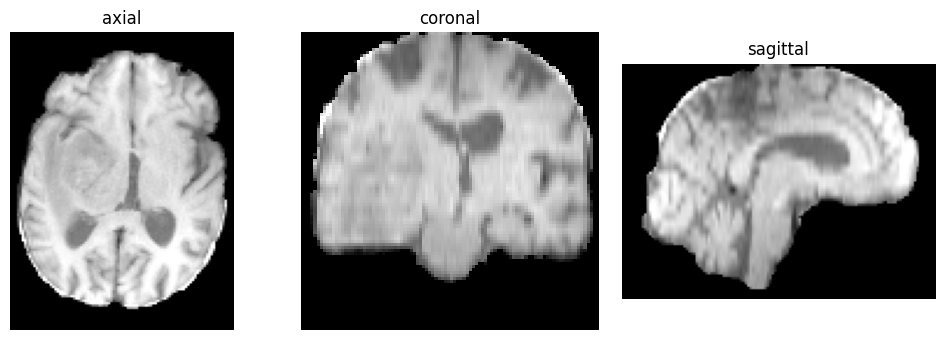

In [8]:
# ---- Find BraTS 2023 cases + build datasets ----
BRATS_MODS = ("t1n", "t1c", "t2w", "t2f")

def find_cases(root, mod):
    cases = []
    for p in sorted(glob.glob(os.path.join(root, "**", f"*-{mod}.nii.gz"), recursive=True)):
        if "/._" in p or "__MACOSX" in p:
            continue
        stem = p[: -len(f"-{mod}.nii.gz")]
        d = {"image": p}
        seg = next((s for s in (f"{stem}-seg.nii.gz", f"{stem}-mask-unhealthy.nii.gz") if os.path.exists(s)), None)
        if seg:
            d["label"] = seg                     # tumour segmentation
        if os.path.exists(f"{stem}-mask-healthy.nii.gz"):
            d["healthy"] = f"{stem}-mask-healthy.nii.gz"   # official inpainting mask (Local Inpainting set)
        cases.append(d)
    return cases

files = find_cases(CFG["data_dir"], CFG["modality"])
if not files:
    found = {m: len(find_cases(CFG["data_dir"], m)) for m in BRATS_MODS}
    print(f"No '{CFG['modality']}' images found; available: {found}")
    CFG["modality"] = max(found, key=found.get)
    files = find_cases(CFG["data_dir"], CFG["modality"])
assert files, f"No BraTS NIfTI files found under {CFG['data_dir']}"

# keep only the extra keys that every case has, so all items share the same structure
extra_keys = [k for k in ("label", "healthy") if all(k in d for d in files)]
files = [{k: d[k] for k in ["image"] + extra_keys} for d in files]
keys = ["image"] + extra_keys
print(f"modality: {CFG['modality']} | cases: {len(files)} | keys: {keys}")
print("example:", files[0])

random.Random(CFG["seed"]).shuffle(files)
n1, n2, n3 = CFG["n_train"], CFG["n_val"], CFG["n_test"]
train_files, val_files, test_files = files[:n1], files[n1:n1 + n2], files[n1 + n2:n1 + n2 + n3]
print(f"train {len(train_files)} | val {len(val_files)} | test {len(test_files)}")

base_tf = [
    T.LoadImaged(keys=keys, image_only=True),
    T.EnsureChannelFirstd(keys=keys),
    T.Orientationd(keys=keys, axcodes="RAS"),
    T.Spacingd(keys=keys, pixdim=CFG["spacing"], mode=["bilinear"] + ["nearest"] * len(extra_keys)),
    T.ScaleIntensityRangePercentilesd(keys="image", lower=0, upper=99.5, b_min=0.0, b_max=1.0, clip=True),
    T.CropForegroundd(keys=keys, source_key="image", margin=2),
    T.ResizeWithPadOrCropd(keys=keys, spatial_size=CFG["vol_size"]),
    T.EnsureTyped(keys=keys, dtype=torch.float32),
]
train_tf = T.Compose(base_tf + (
    [T.DeleteItemsd(keys=extra_keys)] if extra_keys else []) + [
    T.RandSpatialCropd(keys="image", roi_size=CFG["patch"], random_size=False),
    T.RandFlipd(keys="image", prob=0.5, spatial_axis=0),   # left-right flip
])
eval_tf = T.Compose(base_tf)

train_ds = CacheDataset(train_files, transform=train_tf, cache_rate=1.0, num_workers=CFG["num_workers"])
val_ds = CacheDataset(val_files, transform=eval_tf, cache_rate=1.0, num_workers=CFG["num_workers"])
test_ds = CacheDataset(test_files, transform=eval_tf, cache_rate=1.0, num_workers=CFG["num_workers"])
train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True, num_workers=2,
                          persistent_workers=True, drop_last=True)

v = to_t(test_ds[0]["image"])[0].numpy()
print("volume shape:", v.shape, "range:", v.min().round(3), v.max().round(3))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for a, sl, t in zip(axes, [v[:, :, v.shape[2] // 2], v[:, v.shape[1] // 2, :], v[v.shape[0] // 2]],
                    ["axial", "coronal", "sagittal"]):
    a.imshow(np.rot90(sl), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

mask volume fraction of brain (mean): {'ellipsoid': 0.009, 'tumour': 0.0947}


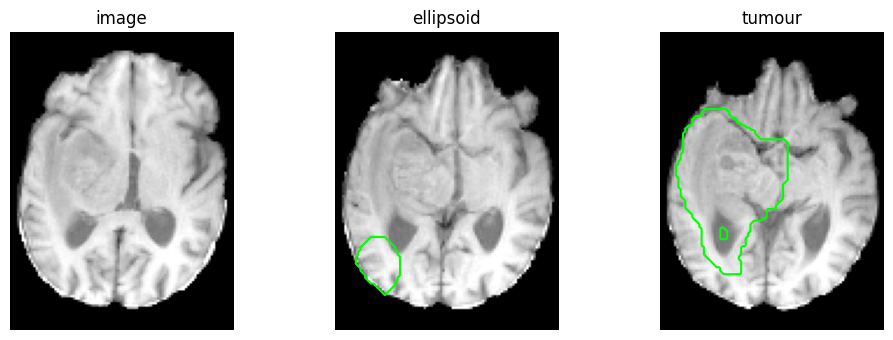

In [9]:
# ---- Inpainting masks for the test set (fixed seed, shared by all VAEs) ----
def ellipsoid_mask(brain, rng, r_range):
    """Random ellipsoid centred on a brain voxel, clipped to the brain."""
    _, _, X, Y, Z = brain.shape
    coords = torch.nonzero(brain[0, 0] > 0)
    c = coords[rng.integers(len(coords))].tolist()
    r = rng.uniform(*r_range, size=3)
    gx, gy, gz = torch.meshgrid(torch.arange(X, device=brain.device), torch.arange(Y, device=brain.device),
                                torch.arange(Z, device=brain.device), indexing="ij")
    e = ((gx - c[0]) / r[0]) ** 2 + ((gy - c[1]) / r[1]) ** 2 + ((gz - c[2]) / r[2]) ** 2 <= 1
    return (e[None, None].float() * brain)

test_masks = []
rng = np.random.default_rng(CFG["seed"])
for i in range(len(test_ds)):
    item = test_ds[i]
    x = to_t(item["image"])[None].float().to(device)
    brain = (x > CFG["brain_thr"]).float()
    masks = {"ellipsoid": ellipsoid_mask(brain, rng, CFG["ellipsoid_radius"])}
    if "label" in item:      # tumour-shaped hole (dilated by 2 voxels)
        tum = (to_t(item["label"])[None].float().to(device) > 0).float()
        if tum.sum() > 50:
            masks["tumour"] = F.max_pool3d(tum, 5, stride=1, padding=2) * brain
    if "healthy" in item:    # official BraTS 2023 inpainting mask over healthy tissue
        hm = (to_t(item["healthy"])[None].float().to(device) > 0).float()
        if hm.sum() > 50:
            masks["healthy"] = hm
    test_masks.append(masks)

mask_types = sorted({k for mm in test_masks for k in mm})
print("mask volume fraction of brain (mean):",
      {k: round(float(np.mean([mm[k].sum().item() / (to_t(test_ds[j]['image']) > CFG['brain_thr']).sum().item()
                               for j, mm in enumerate(test_masks) if k in mm])), 4) for k in mask_types})

# preview
x = to_t(test_ds[0]["image"])[0].numpy()
items = [("image", None)] + list(test_masks[0].items())
fig, axes = plt.subplots(1, len(items), figsize=(3.4 * len(items), 3.5))
for a, (k, mm) in zip(axes, items):
    zc = x.shape[2] // 2 if mm is None else int(torch.nonzero(mm[0, 0])[:, 2].float().mean())
    a.imshow(np.rot90(x[:, :, zc]), cmap="gray")
    if mm is not None:
        a.contour(np.rot90(mm[0, 0, :, :, zc].cpu().numpy()), levels=[0.5], colors="lime")
    a.set_title(k); a.axis("off")
plt.tight_layout(); plt.show()

## 5. The four VAEs

All four are set to the **same 64× compression** (4 latent channels), so differences come from architecture and training rather than latent size.

| # | Model | Type | Downsampling | Weights |
|---|---|---|---|---|
| 1 | MONAI `AutoencoderKL` | continuous KL-VAE, 3D | 4×4×4 | trained here (L1 + perceptual + KL + patch-GAN) |
| 2 | MONAI `VQVAE` | vector-quantized, 3D | 4×4×4 | trained here (L1 + perceptual + VQ + patch-GAN) |
| 3 | MAISI `AutoencoderKlMaisi` | continuous KL-VAE, 3D | 4×4×4 | NVIDIA pretrained (CT + MRI), zero-shot |
| 4 | SD `sd-vae-ft-mse` | continuous KL-VAE, **2D** per axial slice | 8×8×1 | Stability pretrained (natural images), zero-shot |

Training defaults (`CFG`) are sized for a Colab T4. Increase `epochs` for a stronger result. Checkpoints are reused when you rerun.

In [10]:
# ---- Model builders + common wrapper ----
from monai.networks.nets import AutoencoderKL, VQVAE

def build(cls, **kw):
    """Instantiate across MONAI versions (`channels` vs legacy `num_channels`, drop unknown kwargs)."""
    params = inspect.signature(cls.__init__).parameters
    if "channels" in kw and "channels" not in params and "num_channels" in params:
        kw["num_channels"] = kw.pop("channels")
    if "num_channels" in kw and "num_channels" not in params and "channels" in params:
        kw["channels"] = kw.pop("num_channels")
    if not any(p.kind == p.VAR_KEYWORD for p in params.values()):
        dropped = [k for k in kw if k not in params]
        for k in dropped:
            kw.pop(k)
        if dropped:
            print(f"[build] {cls.__name__}: ignoring unsupported args {dropped}")
    return cls(**kw)

def make_kl3d():
    # 3 levels -> 4x downsampling per axis, 4 latent channels => 64x compression (same as MAISI / SD slice-wise)
    return build(AutoencoderKL, spatial_dims=3, in_channels=1, out_channels=1,
                 channels=(32, 64, 128), num_res_blocks=(2, 2, 2), latent_channels=4,
                 norm_num_groups=32, attention_levels=(False, False, False),
                 with_encoder_nonlocal_attn=False, with_decoder_nonlocal_attn=False)

def make_vq3d():
    # 2 stride-2 levels -> 4x per axis, 4-dim codebook vectors => same 64x compression
    return build(VQVAE, spatial_dims=3, in_channels=1, out_channels=1,
                 channels=(64, 128), num_res_channels=(64, 128), num_res_layers=2,
                 downsample_parameters=((2, 4, 1, 1), (2, 4, 1, 1)),
                 upsample_parameters=((2, 4, 1, 1, 0), (2, 4, 1, 1, 0)),
                 num_embeddings=CFG["vq_codebook"], embedding_dim=4)

def monai_kl_fns(model):
    def enc(x):
        with amp():
            z_mu, _ = model.encode(x)    # deterministic: use the posterior mean
        return z_mu.float()
    def dec(z):
        with amp():
            return model.decode(z)
    return enc, dec

def monai_vq_fns(model):
    def enc(x):
        with amp():
            return model.encode_stage_2_inputs(x).float()   # quantized latent
    def dec(z):
        with amp():
            return model.decode_stage_2_outputs(z)          # re-quantizes, then decodes
    return enc, dec

class VAEWrapper:
    """Uniform interface: encode/decode volumes (B,1,X,Y,Z) in [0,1]; map image masks to latent masks."""
    def __init__(self, name, model, factor, enc_fn, dec_fn):
        self.name, self.model, self.factor = name, model, factor
        self._enc, self._dec = enc_fn, dec_fn
        self.n_params = sum(p.numel() for p in model.parameters())

    @torch.no_grad()
    def encode(self, x):
        return self._enc(x)

    @torch.no_grad()
    def decode(self, z):
        return self._dec(z).float().clamp(0, 1)

    def latent_mask(self, m):
        # max-pool = any image voxel in the hole marks the whole latent cell as hole (no leakage at edges)
        return F.max_pool3d(m, kernel_size=self.factor, stride=self.factor)

In [11]:
# ---- Shared training loop for the two from-scratch 3D autoencoders ----
# L1 + perceptual (2.5D SqueezeNet LPIPS) + KL or VQ commitment loss, + patch-GAN after `adv_start` epochs.
from monai.networks.nets import PatchDiscriminator
from monai.losses import PerceptualLoss, PatchAdversarialLoss

def kl_loss(z_mu, z_sigma):
    kl = 0.5 * torch.sum(z_mu.pow(2) + z_sigma.pow(2) - torch.log(z_sigma.pow(2) + 1e-8) - 1,
                         dim=list(range(1, z_mu.ndim)))
    return kl.mean()

@torch.no_grad()
def val_l1(model, kind):
    model.eval()
    tot = 0.0
    for i in range(len(val_ds)):
        x = to_t(val_ds[i]["image"])[None].float().to(device)
        with amp():
            if kind == "kl":
                z_mu, _ = model.encode(x)
                r = model.decode(z_mu)
            else:
                r, _ = model(x)
        tot += F.l1_loss(r.float().clamp(0, 1), x).item()
    model.train()
    return tot / len(val_ds)

def train_autoencoder(name, model, kind):
    ckpt = os.path.join(CFG["ckpt_dir"], f"{name}.pt")
    model = model.to(device)
    if os.path.exists(ckpt) and not CFG["retrain"]:
        st = torch.load(ckpt, map_location=device, weights_only=False)
        model.load_state_dict(st["model"])
        print(f"[{name}] loaded checkpoint (val L1 {st['val_l1']:.4f}) — set CFG['retrain']=True to retrain")
        return model.eval(), st["history"]

    print(f"[{name}] {sum(p.numel() for p in model.parameters())/1e6:.2f}M params")
    disc = build(PatchDiscriminator, spatial_dims=3, num_layers_d=3, channels=32,
                 in_channels=1, out_channels=1).to(device)
    perc = PerceptualLoss(spatial_dims=3, network_type="squeeze", is_fake_3d=True, fake_3d_ratio=0.2).to(device)
    adv = PatchAdversarialLoss(criterion="least_squares")
    opt_g = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    opt_d = torch.optim.Adam(disc.parameters(), lr=CFG["lr"])
    sc_g = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    sc_d = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

    hist = dict(epoch=[], train_l1=[], val_epoch=[], val_l1=[])
    best = float("inf")
    for ep in range(CFG["epochs"]):
        model.train()
        use_adv = ep >= CFG["adv_start"]
        t0, l1s = time.time(), []
        pbar = tqdm(train_loader, desc=f"{name} {ep+1}/{CFG['epochs']}", leave=False)
        for batch in pbar:
            x = to_t(batch["image"]).float().to(device)

            # --- generator / autoencoder step ---
            opt_g.zero_grad(set_to_none=True)
            with amp():
                if kind == "kl":
                    recon, z_mu, z_sigma = model(x)
                    reg = CFG["kl_weight"] * kl_loss(z_mu.float(), z_sigma.float())
                else:
                    recon, q_loss = model(x)
                    reg = q_loss.float()
                recon = recon.float()
                l1 = F.l1_loss(recon, x)
                loss_g = l1 + CFG["perc_weight"] * perc(recon, x) + reg
                if use_adv:
                    logits_fake = disc(recon.contiguous())[-1]
                    loss_g = loss_g + CFG["adv_weight"] * adv(logits_fake, target_is_real=True, for_discriminator=False)
            sc_g.scale(loss_g).backward()
            sc_g.step(opt_g); sc_g.update()

            # --- discriminator step ---
            if use_adv:
                opt_d.zero_grad(set_to_none=True)
                with amp():
                    lf = disc(recon.detach().contiguous())[-1]
                    lr_ = disc(x.contiguous())[-1]
                    loss_d = CFG["adv_weight"] * 0.5 * (
                        adv(lf, target_is_real=False, for_discriminator=True)
                        + adv(lr_, target_is_real=True, for_discriminator=True))
                sc_d.scale(loss_d).backward()
                sc_d.step(opt_d); sc_d.update()

            l1s.append(l1.item())
            pbar.set_postfix(l1=f"{l1.item():.4f}", adv=use_adv)

        hist["epoch"].append(ep + 1); hist["train_l1"].append(float(np.mean(l1s)))
        if (ep + 1) % CFG["val_every"] == 0 or ep + 1 == CFG["epochs"]:
            v = val_l1(model, kind)
            hist["val_epoch"].append(ep + 1); hist["val_l1"].append(v)
            tag = ""
            if v < best:
                best, tag = v, "  *best*"
                torch.save({"model": model.state_dict(), "history": hist, "val_l1": v}, ckpt)
            print(f"[{name}] ep {ep+1:3d}  train L1 {hist['train_l1'][-1]:.4f}  val L1 {v:.4f}  "
                  f"({time.time()-t0:.0f}s/ep){tag}")

    st = torch.load(ckpt, map_location=device, weights_only=False)   # restore best weights
    model.load_state_dict(st["model"])
    st["history"] = hist
    torch.save(st, ckpt)
    del disc, perc, opt_g, opt_d
    gc.collect(); torch.cuda.empty_cache()
    return model.eval(), hist

In [12]:
# ---- 5.1  Train the 3D KL-VAE (~20-40 min on a T4 with default CFG; skipped if a checkpoint exists) ----
kl_model, kl_hist = train_autoencoder("kl3d", make_kl3d(), kind="kl")

[kl3d] 5.25M params
Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /root/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth


100%|██████████| 4.73M/4.73M [00:00<00:00, 87.3MB/s]


kl3d 1/60:   0%|          | 0/60 [00:00<?, ?it/s]

kl3d 2/60:   0%|          | 0/60 [00:00<?, ?it/s]

kl3d 3/60:   0%|          | 0/60 [00:00<?, ?it/s]

...

kl3d 57/60:   0%|          | 0/60 [00:00<?, ?it/s]

kl3d 58/60:   0%|          | 0/60 [00:00<?, ?it/s]

kl3d 59/60:   0%|          | 0/60 [00:00<?, ?it/s]

kl3d 60/60:   0%|          | 0/60 [00:00<?, ?it/s]

[kl3d] ep  60  train L1 0.0472  val L1 0.0345  (49s/ep)  *best*


In [13]:
# ---- 5.2  Train the 3D VQ-VAE (~same budget) ----
vq_model, vq_hist = train_autoencoder("vq3d", make_vq3d(), kind="vq")

[vq3d] 5.51M params


vq3d 1/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 2/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 3/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 4/60:   0%|          | 0/60 [00:00<?, ?it/s]

...

vq3d 57/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 58/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 59/60:   0%|          | 0/60 [00:00<?, ?it/s]

vq3d 60/60:   0%|          | 0/60 [00:00<?, ?it/s]

[vq3d] ep  60  train L1 0.0300  val L1 0.0173  (15s/ep)


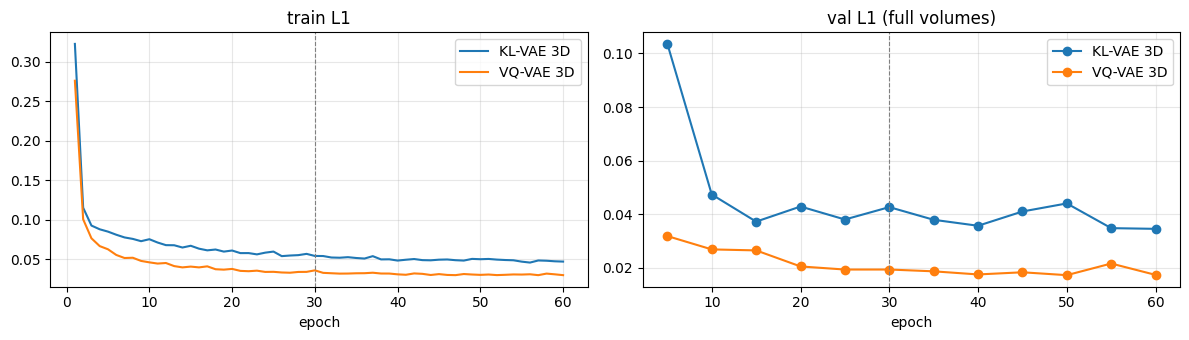

In [14]:
# ---- Training curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, h in [("KL-VAE 3D", kl_hist), ("VQ-VAE 3D", vq_hist)]:
    axes[0].plot(h["epoch"], h["train_l1"], label=name)
    axes[1].plot(h["val_epoch"], h["val_l1"], "o-", label=name)
axes[0].set_title("train L1"); axes[1].set_title("val L1 (full volumes)")
for a in axes:
    a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend()
if CFG["adv_start"] < CFG["epochs"]:
    for a in axes:
        a.axvline(CFG["adv_start"], ls="--", c="gray", lw=0.8)
plt.tight_layout(); plt.show()

In [15]:
# ---- 5.3  MAISI VAE (NVIDIA / MONAI, pretrained on large CT + MRI collections) — zero-shot ----
from monai.apps.generation.maisi.networks.autoencoderkl_maisi import AutoencoderKlMaisi

maisi = build(
    AutoencoderKlMaisi,
    spatial_dims=3, in_channels=1, out_channels=1, latent_channels=4,
    channels=(64, 128, 256), num_res_blocks=(2, 2, 2),
    norm_num_groups=32, norm_eps=1e-6, attention_levels=(False, False, False),
    with_encoder_nonlocal_attn=False, with_decoder_nonlocal_attn=False,
    use_checkpointing=False, use_convtranspose=False,
    norm_float16=True, num_splits=4, dim_split=1,
)

maisi_path = os.path.join(CFG["ckpt_dir"], "maisi_autoencoder.pt")
if not os.path.exists(maisi_path):
    try:
        download_url(CFG["maisi_url"], maisi_path)
    except Exception as e:  # fallback: pull the whole MONAI bundle and find the autoencoder weights
        print("Direct download failed, falling back to the MONAI bundle:", e)
        from monai.bundle import download as bundle_download
        bdir = os.path.join(CFG["ckpt_dir"], "bundles")
        bundle_download(name="maisi_ct_generative", bundle_dir=bdir)
        cands = sorted(glob.glob(f"{bdir}/maisi_ct_generative/models/autoencoder*.pt"))
        assert cands, "MAISI autoencoder weights not found in bundle"
        maisi_path = cands[0]

sd_ = torch.load(maisi_path, map_location="cpu", weights_only=False)
for k in ("state_dict", "autoencoder", "model"):
    if isinstance(sd_, dict) and isinstance(sd_.get(k), dict):
        sd_ = sd_[k]
sd_ = {(k[7:] if k.startswith("module.") else k): v for k, v in sd_.items()}
try:
    maisi.load_state_dict(sd_, strict=True)
    print("MAISI weights loaded (strict).")
except RuntimeError as e:
    print("Strict load failed, trying legacy key mapping…", str(e)[:300])
    maisi.load_old_state_dict(sd_)
    print("MAISI weights loaded (legacy mapping).")
maisi = maisi.to(device).eval()
del sd_

maisi_autoencoder.pt: 80.0MB [00:02, 40.1MB/s]                            

2026-10-09 14:33:30,717 - INFO - Downloaded: /content/vae_bench/ckpts/maisi_autoencoder.pt


MAISI weights loaded (strict).


In [16]:
# ---- 5.4  Stable Diffusion VAE, applied slice-wise (axial) — 2D baseline ----
from diffusers import AutoencoderKL as SDAutoencoderKL

sd_vae = SDAutoencoderKL.from_pretrained(CFG["sd_vae_id"], torch_dtype=torch.float16).to(device).eval()

def sd_enc(x, bs=16):
    """(B,1,X,Y,Z) in [0,1] -> (B,4,X/8,Y/8,Z): each axial slice encoded independently."""
    B, _, X, Y, Z = x.shape
    s = x.permute(0, 4, 1, 2, 3).reshape(B * Z, 1, X, Y)
    s = (s * 2 - 1).repeat(1, 3, 1, 1).half()
    lat = torch.cat([sd_vae.encode(s[k:k + bs]).latent_dist.mean for k in range(0, len(s), bs)])
    return lat.reshape(B, Z, 4, X // 8, Y // 8).permute(0, 2, 3, 4, 1).float()

def sd_dec(z, bs=16):
    B, C, x8, y8, Z = z.shape
    s = z.permute(0, 4, 1, 2, 3).reshape(B * Z, C, x8, y8).half()
    img = torch.cat([sd_vae.decode(s[k:k + bs]).sample for k in range(0, len(s), bs)])
    img = (img.float().mean(1, keepdim=True) + 1) / 2
    return img.reshape(B, Z, 1, x8 * 8, y8 * 8).permute(0, 2, 3, 4, 1)

# ---- All four contestants behind one interface ----
wrappers = [
    VAEWrapper("KL-VAE 3D (trained)", kl_model, (4, 4, 4), *monai_kl_fns(kl_model)),
    VAEWrapper("VQ-VAE 3D (trained)", vq_model, (4, 4, 4), *monai_vq_fns(vq_model)),
    VAEWrapper("MAISI VAE (pretrained)", maisi, (4, 4, 4), *monai_kl_fns(maisi)),
    VAEWrapper("SD-VAE 2D slice-wise", sd_vae, (8, 8, 1), sd_enc, sd_dec),
]

# sanity check: shapes + latent-mask alignment
x = to_t(test_ds[0]["image"])[None].float().to(device)
m = test_masks[0]["ellipsoid"]
for w in wrappers:
    z = w.encode(x); r = w.decode(z)
    assert w.latent_mask(m).shape[2:] == z.shape[2:], (w.name, z.shape)
    print(f"{w.name:28s} latent {tuple(z.shape[1:])}  recon {tuple(r.shape[1:])}  "
          f"params {w.n_params/1e6:.1f}M  quick L1 {F.l1_loss(r, x).item():.4f}")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

KL-VAE 3D (trained)          latent (4, 24, 32, 24)  recon (1, 96, 128, 96)  params 5.3M  quick L1 0.0328
VQ-VAE 3D (trained)          latent (4, 24, 32, 24)  recon (1, 96, 128, 96)  params 5.5M  quick L1 0.0192
MAISI VAE (pretrained)       latent (4, 24, 32, 24)  recon (1, 96, 128, 96)  params 20.9M  quick L1 0.0241
SD-VAE 2D slice-wise         latent (4, 12, 16, 96)  recon (1, 96, 128, 96)  params 83.7M  quick L1 0.0233


## 6. Evaluation protocol

Every metric is computed on **full held-out test volumes** (96×128×96 at 1.5 mm).

1. **Reconstruction:** PSNR and MAE inside the brain, 3D SSIM, 2.5D LPIPS (axial, coronal and sagittal slices), and gradient error split into **in-plane (xy)** and **through-plane (z)**. The z/xy ratio exposes slice-wise inconsistency.
2. **Oracle latent inpainting:** simulates a *perfect* diffusion model to isolate the VAE's contribution:
   - `z_known = E(x · (1−m))` is the latent of the image with the hole zeroed, as the diffusion model would see it.
   - `m_lat = maxpool(m)` is the mask at latent resolution. Max-pooling means any touched latent voxel counts as hole.
   - `z = m_lat · E(x) + (1−m_lat) · z_known`, then `x̂ = D(z)` with pixel paste-back `m·x̂ + (1−m)·x`.
   - Reported metrics: hole PSNR/MAE, **shell_MAE** (how much known tissue just outside the hole changes vs the clean reconstruction, i.e. leakage) and **seam_grad_err** (gradient-magnitude error across the boundary).
   - Mask types: random **ellipsoids** inside the brain, **tumour**-shaped masks (dilated BraTS segmentation) and, if your archive is the BraTS 2023 Local Inpainting set, the official **healthy**-tissue masks. The healthy masks are the closest match to the challenge task.
3. **Latent-noise robustness:** decode `z + σ·std(z)·ε` with σ ∈ {0, 0.1, 0.2, 0.4, 0.8}.
4. **Efficiency:** parameter count, latent shape, compression ratio, encode/decode time, peak GPU memory, and the latent **scale factor** for the diffusion stage.

In [17]:
# ---- Metric helpers ----
import lpips
from monai.metrics import SSIMMetric

lpips_net = lpips.LPIPS(net="alex", verbose=False).to(device).eval()
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def mmean(t, m):
    return ((t * m).sum() / m.sum().clamp_min(1.0)).item()

def psnr(a, b, m):
    mse = mmean((a.float().clamp(0, 1) - b) ** 2, m)
    return 10 * math.log10(1.0 / max(mse, 1e-10))

def dilate(m, r):
    return F.max_pool3d(m, 2 * r + 1, stride=1, padding=r)

def erode(m, r):
    return 1 - dilate(1 - m, r)

def grads(x):  # forward differences along X, Y, Z (Z = axial slice axis)
    gx = F.pad(x[:, :, 1:] - x[:, :, :-1], (0, 0, 0, 0, 0, 1))
    gy = F.pad(x[:, :, :, 1:] - x[:, :, :, :-1], (0, 0, 0, 1, 0, 0))
    gz = F.pad(x[..., 1:] - x[..., :-1], (0, 1, 0, 0, 0, 0))
    return gx, gy, gz

def grad_mag(x):
    gx, gy, gz = grads(x)
    return torch.sqrt(gx ** 2 + gy ** 2 + gz ** 2 + 1e-12)

@torch.no_grad()
def lpips_25d(a, b, brain, step=4, bs=32):
    """LPIPS averaged over axial/coronal/sagittal slices that contain brain."""
    vals = []
    for ax in (2, 3, 4):
        idx = [i for i in range(0, a.shape[ax], step) if brain.select(ax, i).sum() > 100]
        if not idx:
            continue
        sa = torch.cat([a.select(ax, i) for i in idx]).float().clamp(0, 1)
        sb = torch.cat([b.select(ax, i) for i in idx]).float()
        for k in range(0, len(idx), bs):
            pa = sa[k:k + bs].repeat(1, 3, 1, 1) * 2 - 1
            pb = sb[k:k + bs].repeat(1, 3, 1, 1) * 2 - 1
            vals.append(lpips_net(pa, pb).flatten())
    return torch.cat(vals).mean().item()

@torch.no_grad()
def recon_metrics(rec, x, brain):
    rec = rec.float().clamp(0, 1)
    ge = [mmean((p - q).abs(), brain) for p, q in zip(grads(rec), grads(x))]
    return {
        "PSNR_brain": psnr(rec, x, brain),
        "SSIM": ssim_metric(rec, x).mean().item(),
        "MAE_brain": mmean((rec - x).abs(), brain),
        "LPIPS_2.5D": lpips_25d(rec, x, brain),
        "GradErr_xy": (ge[0] + ge[1]) / 2,   # in-plane gradient error
        "GradErr_z": ge[2],                  # through-plane (slice-to-slice) gradient error
    }

@torch.no_grad()
def oracle_latent(w, x, m):
    """What a *perfect* latent diffusion inpainter would produce:
    true latent inside the latent-space hole, latent of the masked image outside."""
    z_gt = w.encode(x)
    z_known = w.encode(x * (1 - m))
    ml = w.latent_mask(m).to(z_gt.dtype)
    return ml * z_gt + (1 - ml) * z_known

@torch.no_grad()
def inpaint_metrics(inp, rec, x, m):
    inp = inp.float().clamp(0, 1)
    rec = rec.float().clamp(0, 1)
    shell = dilate(m, 3) - m                 # 3-voxel ring of known tissue around the hole
    band = dilate(m, 2) - erode(m, 2)        # band straddling the hole boundary
    final = m * inp + (1 - m) * x            # standard pixel-space paste-back
    return {
        "hole_PSNR": psnr(inp, x, m),
        "hole_MAE": mmean((inp - x).abs(), m),
        "shell_MAE": mmean((inp - rec).abs(), shell),   # leakage: change vs clean recon outside the hole
        "seam_grad_err": mmean((grad_mag(final) - grad_mag(x)).abs(), band),
    }

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 112MB/s] 


In [18]:
# ---- Run the full benchmark on the test set ----
rec_rows, inp_rows, noise_rows, eff_rows = [], [], [], []

for w in wrappers:
    s1 = s2 = n_el = 0.0
    enc_t, dec_t = [], []
    if device.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    for i in tqdm(range(len(test_ds)), desc=w.name):
        x = to_t(test_ds[i]["image"])[None].float().to(device)
        brain = (x > CFG["brain_thr"]).float()

        # 1) reconstruction + timing
        sync(); t0 = time.perf_counter()
        z = w.encode(x)
        sync(); t1 = time.perf_counter()
        rec = w.decode(z)
        sync(); t2 = time.perf_counter()
        if i > 0:  # skip warm-up
            enc_t.append(t1 - t0); dec_t.append(t2 - t1)
        zf = z.float()
        s1 += zf.sum().item(); s2 += (zf ** 2).sum().item(); n_el += zf.numel()
        rec_rows.append(dict(model=w.name, subject=i, **recon_metrics(rec, x, brain)))

        # 2) oracle latent inpainting for each mask type
        for mtype, m in test_masks[i].items():
            inp = w.decode(oracle_latent(w, x, m))
            inp_rows.append(dict(model=w.name, subject=i, mask=mtype, **inpaint_metrics(inp, rec, x, m)))

        # 3) decoder robustness to latent noise
        std_z = zf.std()
        g = torch.Generator(device=zf.device).manual_seed(1000 + i)
        for sigma in CFG["noise_sigmas"]:
            zn = zf + sigma * std_z * torch.randn(zf.shape, generator=g, device=zf.device)
            rn = w.decode(zn.to(z.dtype))
            noise_rows.append(dict(model=w.name, subject=i, sigma=sigma, PSNR_brain=psnr(rn, x, brain)))

    lat_mean = s1 / n_el
    lat_std = math.sqrt(max(s2 / n_el - lat_mean ** 2, 1e-12))
    eff_rows.append(dict(
        model=w.name,
        params_M=round(w.n_params / 1e6, 2),
        latent_shape=str(tuple(z.shape[1:])),
        compression=round(x.numel() / z[0].numel(), 1),
        latent_mean=round(lat_mean, 4),
        latent_std=round(lat_std, 4),
        scale_factor=round(1.0 / lat_std, 4),
        encode_ms=round(1000 * np.mean(enc_t), 1),
        decode_ms=round(1000 * np.mean(dec_t), 1),
        peak_mem_GB=round(torch.cuda.max_memory_allocated() / 1e9, 2) if device.type == "cuda" else None,
    ))
    print(eff_rows[-1])

KL-VAE 3D (trained):   0%|          | 0/24 [00:00<?, ?it/s]

{'model': 'KL-VAE 3D (trained)', 'params_M': 5.25, 'latent_shape': '(4, 24, 32, 24)', 'compression': 16.0, 'latent_mean': -0.0099, 'latent_std': 0.5793, 'scale_factor': 1.7261, 'encode_ms': np.float64(78.1), 'decode_ms': np.float64(146.6), 'peak_mem_GB': 1.6}


VQ-VAE 3D (trained):   0%|          | 0/24 [00:00<?, ?it/s]

{'model': 'VQ-VAE 3D (trained)', 'params_M': 5.51, 'latent_shape': '(4, 24, 32, 24)', 'compression': 16.0, 'latent_mean': -0.1144, 'latent_std': 0.3954, 'scale_factor': 2.5288, 'encode_ms': np.float64(19.1), 'decode_ms': np.float64(24.2), 'peak_mem_GB': 0.83}


MAISI VAE (pretrained):   0%|          | 0/24 [00:00<?, ?it/s]

{'model': 'MAISI VAE (pretrained)', 'params_M': 20.94, 'latent_shape': '(4, 24, 32, 24)', 'compression': 16.0, 'latent_mean': -0.0039, 'latent_std': 0.7152, 'scale_factor': 1.3981, 'encode_ms': np.float64(354.1), 'decode_ms': np.float64(593.4), 'peak_mem_GB': 1.98}


SD-VAE 2D slice-wise:   0%|          | 0/24 [00:00<?, ?it/s]

{'model': 'SD-VAE 2D slice-wise', 'params_M': 83.65, 'latent_shape': '(4, 12, 16, 96)', 'compression': 16.0, 'latent_mean': -0.8901, 'latent_std': 6.671, 'scale_factor': 0.1499, 'encode_ms': np.float64(480.5), 'decode_ms': np.float64(1091.1), 'peak_mem_GB': 1.08}


In [19]:
# ---- Summary tables ----
def summarize(df, by, cols):
    g = df.groupby(by)[cols]
    mean, std = g.mean(), g.std()
    out = mean.copy().astype(object)
    for c in cols:
        out[c] = [f"{m:.4f} ± {s:.4f}" if abs(m) < 1 else f"{m:.2f} ± {s:.2f}"
                  for m, s in zip(mean[c], std[c].fillna(0))]
    return out

df_rec = pd.DataFrame(rec_rows)
df_inp = pd.DataFrame(inp_rows)
df_noise = pd.DataFrame(noise_rows)
df_eff = pd.DataFrame(eff_rows).set_index("model")
df_rec["GradErr_z/xy"] = df_rec["GradErr_z"] / df_rec["GradErr_xy"]

for d, n in [(df_rec, "recon"), (df_inp, "oracle_inpaint"), (df_noise, "latent_noise"), (df_eff, "efficiency")]:
    d.to_csv(f"{CFG['out_dir']}/{n}.csv")

print("=== 1) Reconstruction (test set) ===  PSNR/SSIM ↑, MAE/LPIPS/GradErr ↓")
display(summarize(df_rec, "model", ["PSNR_brain", "SSIM", "MAE_brain", "LPIPS_2.5D", "GradErr_xy", "GradErr_z", "GradErr_z/xy"]))

print("=== 2) Oracle latent inpainting (VAE-only upper bound) ===  hole_PSNR ↑, others ↓")
display(summarize(df_inp, ["mask", "model"], ["hole_PSNR", "hole_MAE", "shell_MAE", "seam_grad_err"]))

print("=== 3) Decoder robustness: PSNR_brain after adding latent noise σ·std(z) ===")
display(df_noise.pivot_table(index="model", columns="sigma", values="PSNR_brain", aggfunc="mean").round(2))

print("=== 4) Latent / efficiency ===")
display(df_eff)

=== 1) Reconstruction (test set) ===  PSNR/SSIM ↑, MAE/LPIPS/GradErr ↓


,PSNR_brain,SSIM,MAE_brain,LPIPS_2.5D,GradErr_xy,GradErr_z,GradErr_z/xy
model,,,,,,,
KL-VAE 3D (trained),18.85 ± 1.56,0.8565 ± 0.0152,0.0911 ± 0.0194,0.0825 ± 0.0135,0.0511 ± 0.0071,0.0476 ± 0.0113,0.9231 ± 0.1331
MAISI VAE (pretrained),25.48 ± 1.23,0.7044 ± 0.0304,0.0373 ± 0.0065,0.0301 ± 0.0030,0.0396 ± 0.0070,0.0337 ± 0.0109,0.8401 ± 0.1906
SD-VAE 2D slice-wise,23.15 ± 1.39,0.8697 ± 0.0178,0.0498 ± 0.0091,0.0435 ± 0.0071,0.0473 ± 0.0084,0.0482 ± 0.0125,1.01 ± 0.14
VQ-VAE 3D (trained),24.42 ± 1.22,0.9190 ± 0.0114,0.0425 ± 0.0075,0.0490 ± 0.0104,0.0455 ± 0.0064,0.0413 ± 0.0105,0.8972 ± 0.1432


=== 2) Oracle latent inpainting (VAE-only upper bound) ===  hole_PSNR ↑, others ↓


hole_PSNR         hole_MAE  \
mask      model                                                   
ellipsoid KL-VAE 3D (trained)     18.55 ± 2.55  0.1046 ± 0.0343   
          MAISI VAE (pretrained)  23.31 ± 1.76  0.0549 ± 0.0104   
          SD-VAE 2D slice-wise    21.98 ± 1.91  0.0592 ± 0.0140   
          VQ-VAE 3D (trained)     25.20 ± 1.95  0.0413 ± 0.0092   
tumour    KL-VAE 3D (trained)     20.01 ± 2.31  0.0854 ± 0.0279   
          MAISI VAE (pretrained)  22.35 ± 1.14  0.0630 ± 0.0081   
          SD-VAE 2D slice-wise    24.14 ± 1.85  0.0454 ± 0.0102   
          VQ-VAE 3D (trained)     26.22 ± 1.60  0.0355 ± 0.0066   

                                        shell_MAE    seam_grad_err  
mask      model                                                     
ellipsoid KL-VAE 3D (trained)     0.0583 ± 0.0127  0.0280 ± 0.0077  
          MAISI VAE (pretrained)  0.0554 ± 0.0128  0.0196 ± 0.0050  
          SD-VAE 2D slice-wise    0.0365 ± 0.0085  0.0235 ± 0.0063  
          VQ-VAE 3D (trained)     0.0348 ± 0.0071  0.0186 ± 0.0053  
tumour    KL-VAE 3D (trained)     0.0581 ± 0.0088  0.0312 ± 0.0069  
          MAISI VAE (pretrained)  0.0899 ± 0.0107  0.0271 ± 0.0048  
          SD-VAE 2D slice-wise    0.0390 ± 0.0066  0.0257 ± 0.0066  
          VQ-VAE 3D (trained)     0.0423 ± 0.0042  0.0230 ± 0.0055

=== 3) Decoder robustness: PSNR_brain after adding latent noise σ·std(z) ===


sigma,0.0,0.1,0.2,0.4,0.8
model,,,,,
KL-VAE 3D (trained),18.85,18.84,18.81,18.68,18.19
MAISI VAE (pretrained),25.48,25.31,24.84,23.21,19.41
SD-VAE 2D slice-wise,23.15,21.31,18.73,14.45,10.31
VQ-VAE 3D (trained),24.42,24.38,23.77,22.21,19.26


=== 4) Latent / efficiency ===


,params_M,latent_shape,compression,latent_mean,latent_std,scale_factor,encode_ms,decode_ms,peak_mem_GB
model,,,,,,,,,
KL-VAE 3D (trained),5.25,"(4, 24, 32, 24)",16.0,-0.0099,0.5793,1.7261,78.1,146.6,1.60
VQ-VAE 3D (trained),5.51,"(4, 24, 32, 24)",16.0,-0.1144,0.3954,2.5288,19.1,24.2,0.83
MAISI VAE (pretrained),20.94,"(4, 24, 32, 24)",16.0,-0.0039,0.7152,1.3981,354.1,593.4,1.98
SD-VAE 2D slice-wise,83.65,"(4, 12, 16, 96)",16.0,-0.8901,6.6710,0.1499,480.5,1091.1,1.08


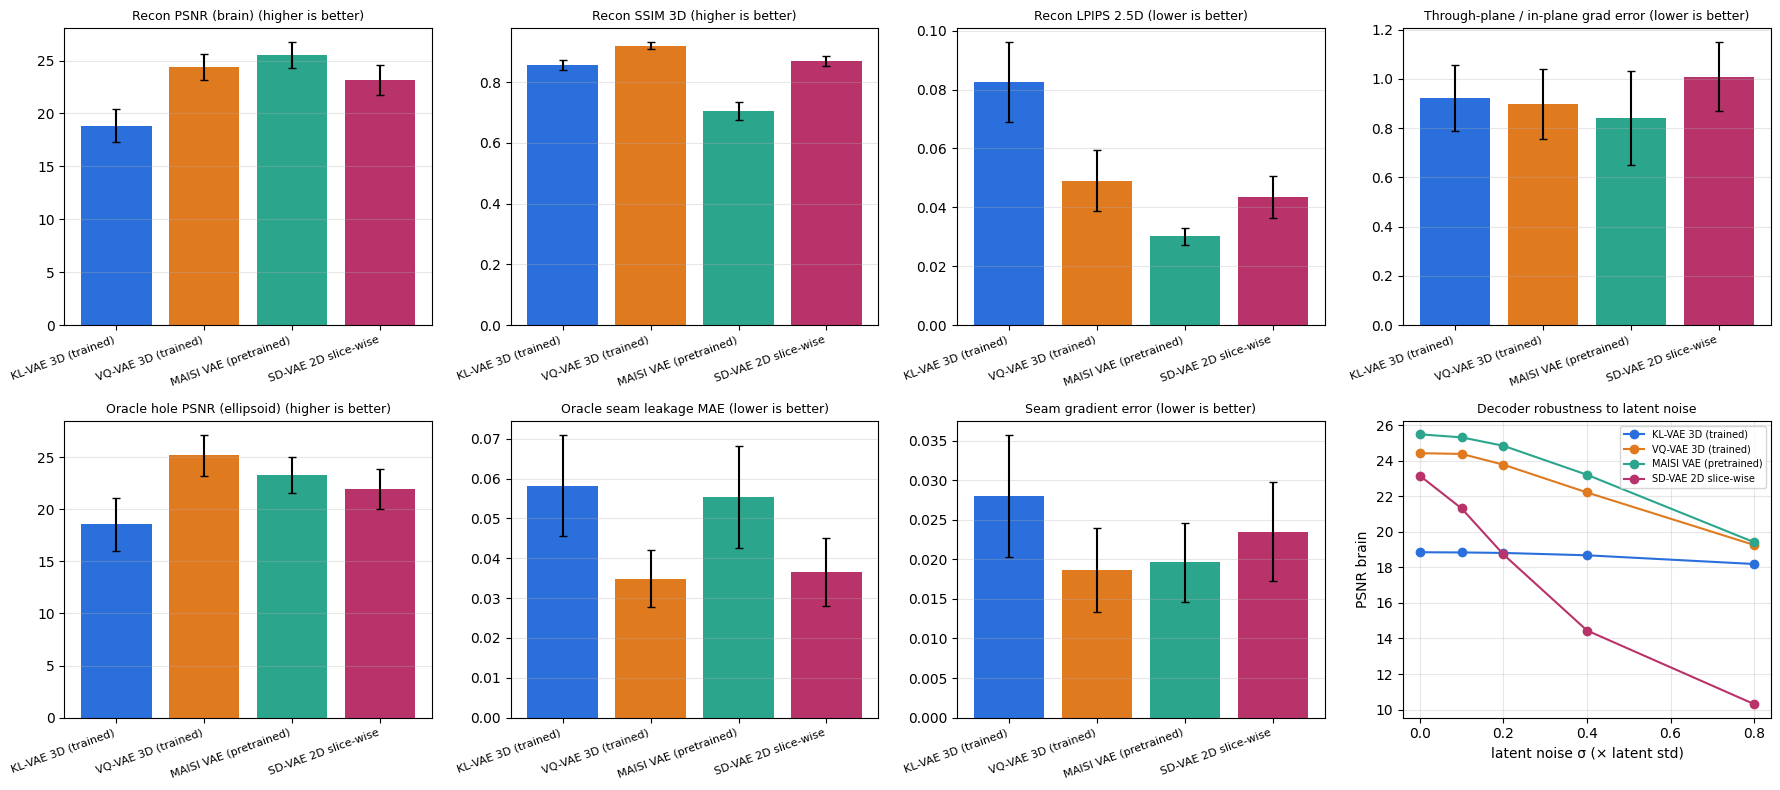

In [20]:
# ---- Plots ----
names = [w.name for w in wrappers]
colors = dict(zip(names, ["#2a6fdb", "#e07a1f", "#2ca58d", "#b8336a"]))

def bar_panel(ax, df, metric, title, lower_better=False):
    g = df.groupby("model")[metric]
    mu, sd = g.mean().reindex(names), g.std().reindex(names)
    ax.bar(range(len(names)), mu.values, yerr=sd.values, capsize=3,
           color=[colors[n] for n in names])
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels(names, rotation=20, ha="right", fontsize=8)
    ax.set_title(f"{title} ({'lower' if lower_better else 'higher'} is better)", fontsize=9)
    ax.grid(axis="y", alpha=0.3)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
bar_panel(axes[0, 0], df_rec, "PSNR_brain", "Recon PSNR (brain)")
bar_panel(axes[0, 1], df_rec, "SSIM", "Recon SSIM 3D")
bar_panel(axes[0, 2], df_rec, "LPIPS_2.5D", "Recon LPIPS 2.5D", True)
bar_panel(axes[0, 3], df_rec, "GradErr_z/xy", "Through-plane / in-plane grad error", True)
ell = df_inp[df_inp["mask"] == "ellipsoid"]
bar_panel(axes[1, 0], ell, "hole_PSNR", "Oracle hole PSNR (ellipsoid)")
bar_panel(axes[1, 1], ell, "shell_MAE", "Oracle seam leakage MAE", True)
bar_panel(axes[1, 2], ell, "seam_grad_err", "Seam gradient error", True)

ax = axes[1, 3]
for n in names:
    d = df_noise[df_noise["model"] == n].groupby("sigma")["PSNR_brain"].mean()
    ax.plot(d.index, d.values, "o-", label=n, color=colors[n])
ax.set_xlabel("latent noise σ (× latent std)"); ax.set_ylabel("PSNR brain")
ax.set_title("Decoder robustness to latent noise", fontsize=9)
ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/metrics.png", dpi=150)
plt.show()

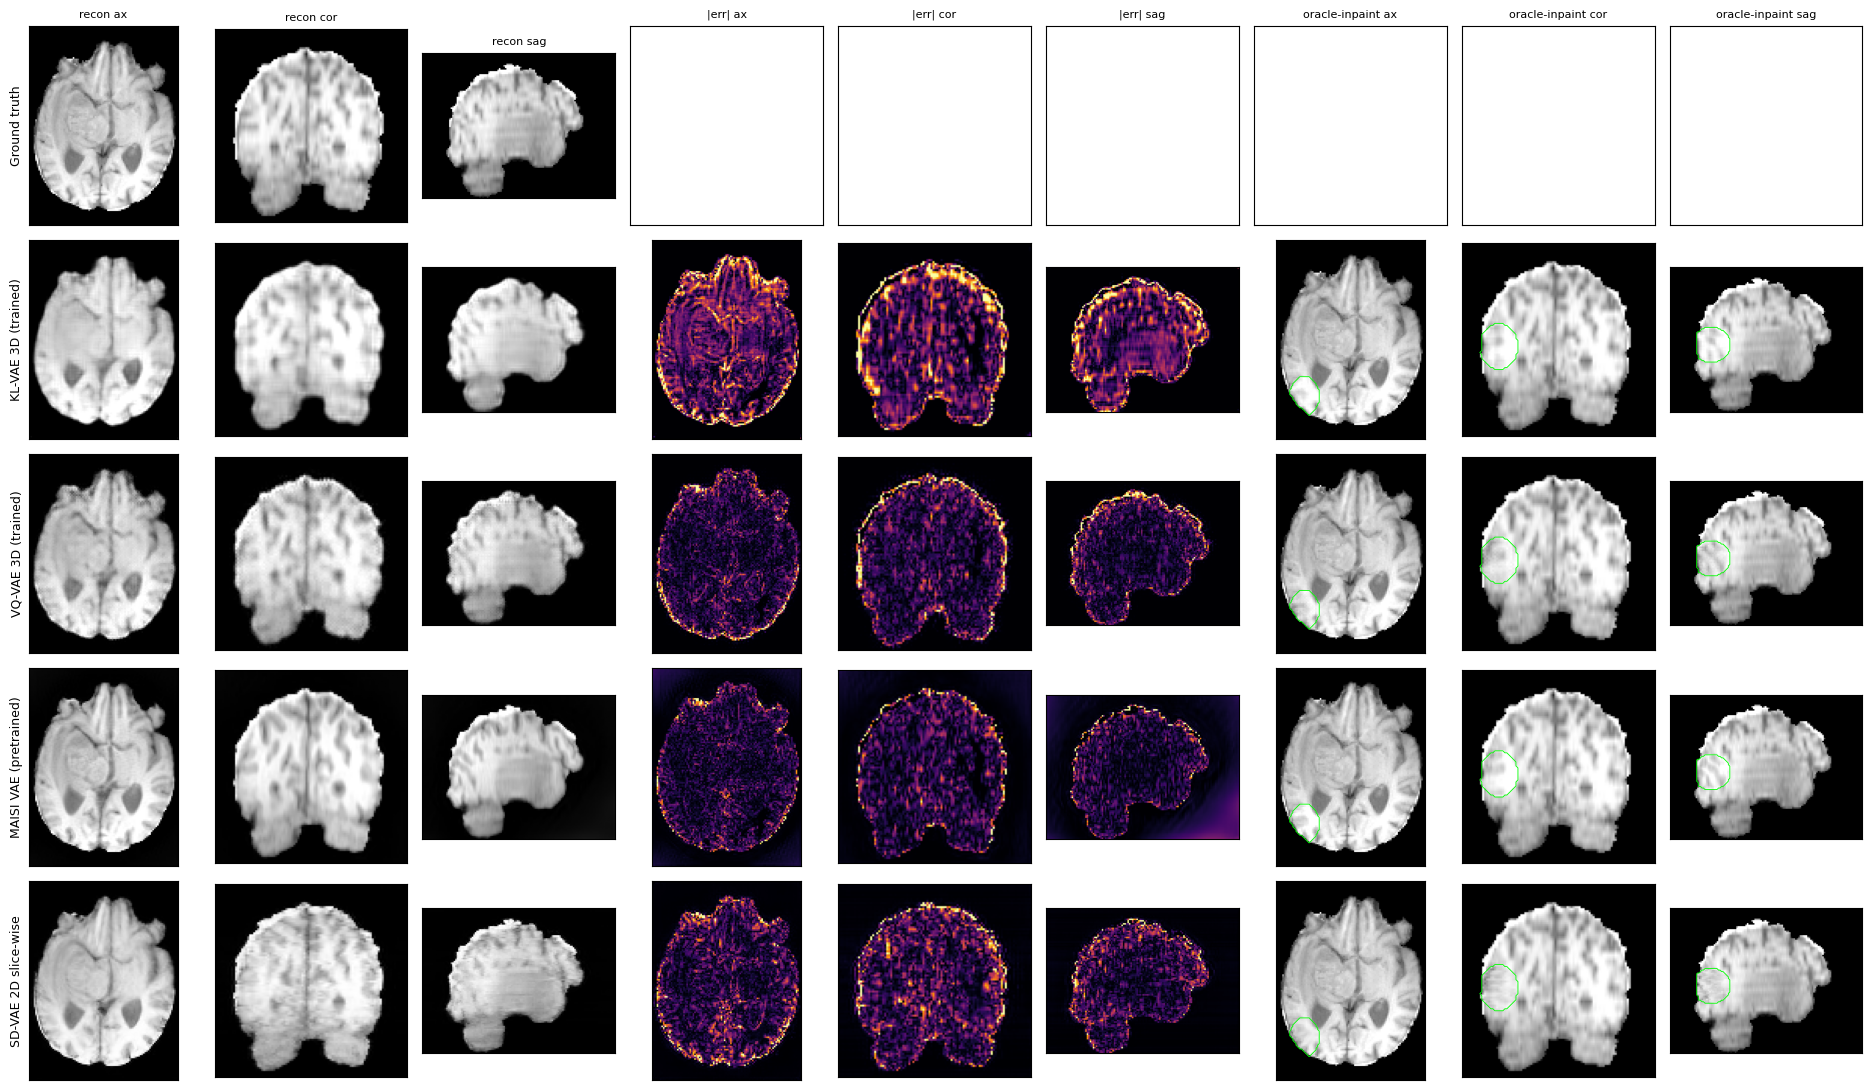

In [21]:
# ---- Visual comparison on one test subject ----
item = test_ds[CFG["viz_index"]]
x = to_t(item["image"])[None].float().to(device)
m = test_masks[CFG["viz_index"]]["ellipsoid"]
cx, cy, cz = [int(v) for v in torch.nonzero(m[0, 0]).float().mean(0)]   # center of the hole

def views(v):  # axial (z), coronal (y), sagittal (x) slices through the hole center
    v = v[0, 0].detach().float().cpu().numpy()
    return [np.rot90(v[:, :, cz]), np.rot90(v[:, cy, :]), np.rot90(v[cx, :, :])]

rows = [("Ground truth", x, None)]
for w in wrappers:
    with torch.no_grad():
        rec = w.decode(w.encode(x))
        z_comp = oracle_latent(w, x, m)
        inp = w.decode(z_comp)
        inp = m * inp + (1 - m) * x
    rows.append((w.name, rec, inp))

ncol = 9
fig, axes = plt.subplots(len(rows), ncol, figsize=(2.1 * ncol, 2.2 * len(rows)))
titles = ["recon ax", "recon cor", "recon sag", "|err| ax", "|err| cor", "|err| sag",
          "oracle-inpaint ax", "oracle-inpaint cor", "oracle-inpaint sag"]
gt_views = views(x)
m_views = views(m)
for r, (name, rec, inp) in enumerate(rows):
    rv = views(rec)
    for c in range(3):
        axes[r, c].imshow(rv[c], cmap="gray", vmin=0, vmax=1)
        if inp is not None:
            axes[r, 3 + c].imshow(np.abs(rv[c] - gt_views[c]), cmap="inferno", vmin=0, vmax=0.25)
            iv = views(inp)
            axes[r, 6 + c].imshow(iv[c], cmap="gray", vmin=0, vmax=1)
            axes[r, 6 + c].contour(m_views[c], levels=[0.5], colors="lime", linewidths=0.6)
    axes[r, 0].set_ylabel(name, fontsize=9)
for c in range(ncol):
    axes[0, c].set_title(titles[c], fontsize=8)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/visual_comparison.png", dpi=150)
plt.show()

## 7. How to read the results / picking a VAE for the diffusion stage

| Question | Look at | Why it matters for latent-diffusion inpainting |
|---|---|---|
| Can the VAE even represent the anatomy? | Recon PSNR / SSIM / LPIPS | It caps image quality. The diffusion model can never do better than its VAE. |
| Does it create slice artifacts? | `GradErr_z` vs `GradErr_xy` | A large z/xy ratio (expected for the 2D SD VAE) shows up as striping in coronal/sagittal views. |
| Best case for inpainting | **Oracle** hole PSNR / MAE | Assumes a *perfect* diffusion model (latent = true latent). The remaining error comes from the VAE alone. |
| Will the inpainted region show seams? | Oracle `shell_MAE`, `seam_grad_err` | Measures how much the empty (zeroed) hole leaks into known tissue through the encoder's receptive field, and how visible the paste-back edge is. |
| How forgiving is the decoder? | Latent-noise PSNR curve | Diffusion samples are never exact. A decoder that degrades gracefully is easier to use. (The VQ decoder re-quantizes, which partly denoises.) |
| Diffusion cost | Latent shape, compression, enc/dec ms, peak memory, `scale_factor` | Multiply latents by `scale_factor` (≈1/std) before training the diffusion UNet. |

**Caveats**
- The KL-3D and VQ-3D models are trained briefly on ~120 volumes. MAISI and SD are used zero-shot, so this compares "pretrained off-the-shelf" against "small and in-domain". For the strongest comparison, also **fine-tune MAISI** on this data.
- MAISI's training data includes public brain MRI, which may overlap with BraTS/MSD. Treat its scores as possibly optimistic.
- The SD VAE operates on axial slices (8× in-plane, 1× through-plane), so it has the **same 64× compression** as the 3D models (4×4×4).

**Next steps:** pick the 1–2 best VAEs, cache the train and test latents (×`scale_factor`), train a 3D `DiffusionModelUNet` (MONAI) on them, and inpaint with RePaint-style latent compositing using the same `latent_mask` (max-pool) used here. Then rerun the benchmark's oracle-inpainting step with real diffusion samples in place of `oracle_latent`.